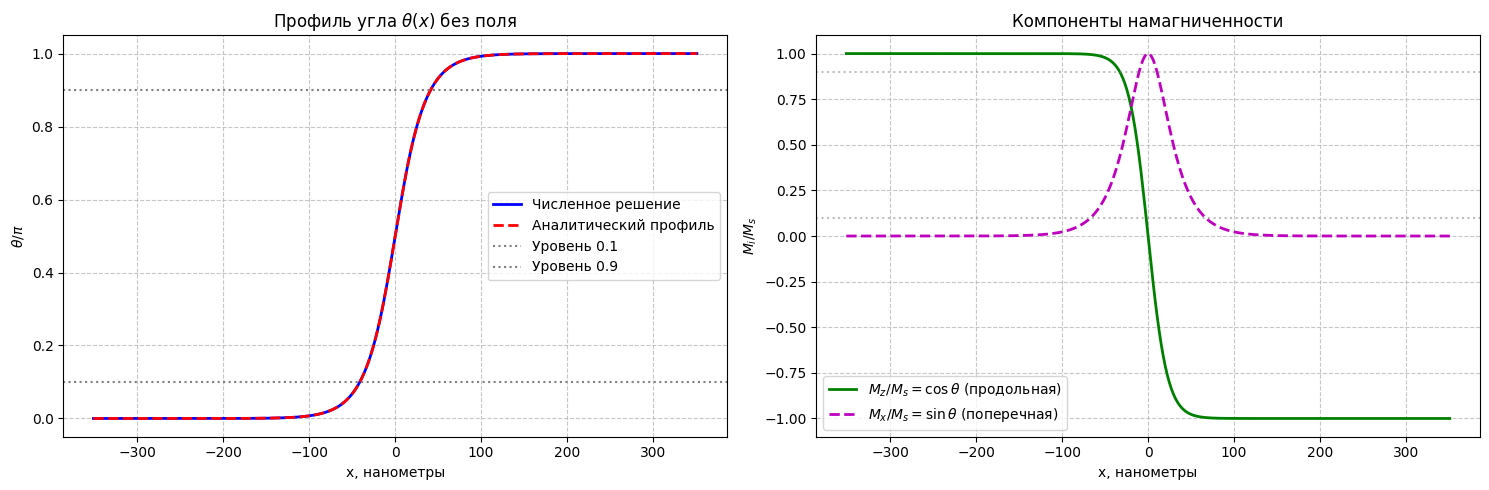

--------------------------------------------------
Ширина границы (аналитическая): 70.25 нм
Ширина границы (численная по 0.1-0.9): 30.70 нм


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_bvp

A = 2.0e-11
K = 4.0e4
Ms = 1.7e6
mu0 = 4 * np.pi * 1e-7

Delta0 = np.sqrt(A / K)
delta0 = np.pi * Delta0

#1.числ.реш
x_nm = np.linspace(-5 * delta0 * 1e9, 5 * delta0 * 1e9, 300)
x_m = x_nm * 1e-9

def ode_system(x, y):
    theta = y[0]
    dtheta_dx = y[1]
    d2theta_dx2 = (K / A) * np.sin(theta) * np.cos(theta)
    return np.vstack((dtheta_dx, d2theta_dx2))

def boundary_conditions(ya, yb):
    return np.array([ya[0] - 0, yb[0] - np.pi])

y_guess = np.zeros((2, x_m.size))
y_guess[0] = 2 * np.arctan(np.exp(x_m / Delta0))

sol = solve_bvp(ode_system, boundary_conditions, x_m, y_guess)
theta_num = sol.sol(x_m)[0]

#2.
Mz_num = np.cos(theta_num)
Mx_num = np.sin(theta_num)

theta_analit = 2 * np.arctan(np.exp(x_m / Delta0))

#3.ширина
theta_09 = np.arccos(0.9)
theta_01 = np.arccos(0.1)

x_09 = np.interp(theta_09, theta_num, x_nm)
x_01 = np.interp(theta_01, theta_num, x_nm)
delta_num = abs(x_01 - x_09)

#4.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

#1график
ax1.plot(x_nm, theta_num / np.pi, 'b-', lw=2, label='Численное решение')
ax1.plot(x_nm, theta_analit / np.pi, 'r--', lw=2, label='Аналитический профиль')
ax1.axhline(0.1, color='gray', linestyle=':', label='Уровень 0.1')
ax1.axhline(0.9, color='gray', linestyle=':', label='Уровень 0.9')
ax1.set_xlabel('x, нанометры')
ax1.set_ylabel(r'$\theta / \pi$')
ax1.set_title(r'Профиль угла $\theta(x)$ без поля')
ax1.grid(True, linestyle='--', alpha=0.7)
ax1.legend()

#2график
ax2.plot(x_nm, Mz_num, 'g-', lw=2, label=r'$M_z/M_s = \cos\theta$ (продольная)')
ax2.plot(x_nm, Mx_num, 'm--', lw=2, label=r'$M_x/M_s = \sin\theta$ (поперечная)')

ax2.axhline(0.9, color='gray', linestyle=':', alpha=0.5)
ax2.axhline(0.1, color='gray', linestyle=':', alpha=0.5)

ax2.set_xlabel('x, нанометры')
ax2.set_ylabel(r'$M_i / M_s$')
ax2.set_title('Компоненты намагниченности')
ax2.grid(True, linestyle='--', alpha=0.7)
ax2.legend()

plt.tight_layout()
plt.show()

#5.
print("-" * 50)
print(f"Ширина границы (аналитическая): {delta0*1e9:.2f} нм")
print(f"Ширина границы (численная по 0.1-0.9): {delta_num:.2f} нм")